Check Dataset

In [2]:
from pathlib import Path

dataset_path = Path("D:\\UOM\\Sem 5\\Pattern\\Assignment03\\RocogniX_Classification_Assignment\\split")

for split in ["train", "validation", "test"]:
    folder = dataset_path / split

    files = list(folder.rglob("*.pgm"))

    print(f"{split}: {len(files)} images")

    print("Example files:")
    for f in files[:5]:
        print("  ", f)

    print()

train: 436 images
Example files:
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_happy_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_happy_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_neutral_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_neutral_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\train\an2i_left_sad_sunglasses_2.pgm

validation: 93 images
Example files:
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_left_angry_open_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_left_angry_sunglasses_2.pgm
   D:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\split\validation\an2i_right_angry_sunglasses

In [3]:
from PIL import Image

for split in ["train", "validation", "test"]:

    files = list((dataset_path / split).rglob("*.pgm"))

    print(f"\n{split}")

    for f in files[:5]:
        img = Image.open(f)
        print(f.name, "→", img.size, img.mode)


train
an2i_left_happy_open_2.pgm → (64, 60) L
an2i_left_happy_sunglasses_2.pgm → (64, 60) L
an2i_left_neutral_open_2.pgm → (64, 60) L
an2i_left_neutral_sunglasses_2.pgm → (64, 60) L
an2i_left_sad_sunglasses_2.pgm → (64, 60) L

validation
an2i_left_angry_open_2.pgm → (64, 60) L
an2i_left_angry_sunglasses_2.pgm → (64, 60) L
an2i_right_angry_sunglasses_2.pgm → (64, 60) L
an2i_right_happy_sunglasses_2.pgm → (64, 60) L
an2i_up_neutral_sunglasses_2.pgm → (64, 60) L

test
an2i_left_sad_open_2.pgm → (64, 60) L
an2i_up_angry_sunglasses_2.pgm → (64, 60) L
an2i_up_happy_sunglasses_2.pgm → (64, 60) L
an2i_up_sad_open_2.pgm → (64, 60) L
at33_left_angry_open_2.pgm → (64, 60) L


In [4]:
from collections import Counter

poses = ["straight", "left", "right", "up"]

for split in ["train", "validation", "test"]:

    files = list((dataset_path / split).rglob("*.pgm"))

    counts = Counter()

    for f in files:
        parts = f.stem.split("_")

        # filename:
        # userid_pose_expression_eyes_scale
        pose = parts[1]

        counts[pose] += 1

    print(f"\n{split}:")
    
    for pose in poses:
        print(f"{pose:8s}: {counts[pose]}")


train:
straight: 109
left    : 105
right   : 113
up      : 109

validation:
straight: 26
left    : 25
right   : 23
up      : 19

test:
straight: 21
left    : 27
right   : 19
up      : 28


Load Dataset into NumPy

In [5]:
from pathlib import Path
from PIL import Image
import numpy as np

# Dataset path
DATASET_PATH = Path("../split")

# Class mapping
CLASS_TO_INDEX = {
    "straight": 0,
    "left": 1,
    "right": 2,
    "up": 3
}

CLASS_NAMES = list(CLASS_TO_INDEX.keys())

def load_dataset(split):
    folder = DATASET_PATH / split

    images = []
    labels = []

    files = sorted(folder.glob("*.pgm"))

    for file in files:
        # Extract pose from filename
        # Example: an2i_left_happy_open_2.pgm
        pose = file.stem.split("_")[1]

        # Convert pose to numerical label
        label = CLASS_TO_INDEX[pose]

        # Load grayscale image
        image = np.array(Image.open(file), dtype=np.float32)

        # Normalize pixels: 0-255 -> 0-1
        image /= 255.0

        # Add channel dimension: (60,64) -> (60,64,1)
        image = np.expand_dims(image, axis=-1)

        images.append(image)
        labels.append(label)

    return np.array(images, dtype=np.float32), np.array(labels, dtype=np.int64)

In [6]:
# Load datasets
X_train, y_train = load_dataset("train")
X_val, y_val = load_dataset("validation")
X_test, y_test = load_dataset("test")


# Display information
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:  ", X_val.shape)
print("y_val:  ", y_val.shape)

print("X_test: ", X_test.shape)
print("y_test: ", y_test.shape)

print("\nPixel range:", X_train.min(), "to", X_train.max())
print("Classes:", CLASS_TO_INDEX)

X_train: (436, 60, 64, 1)
y_train: (436,)
X_val:   (93, 60, 64, 1)
y_val:   (93,)
X_test:  (95, 60, 64, 1)
y_test:  (95,)

Pixel range: 0.0 to 0.9882353
Classes: {'straight': 0, 'left': 1, 'right': 2, 'up': 3}


In [7]:
import os
print(os.getcwd())
print("Dataset path:", DATASET_PATH)

d:\UOM\Sem 5\Pattern\Assignment03\RocogniX_Classification_Assignment\Model_B
Dataset path: ..\split


Visualise the loaded data

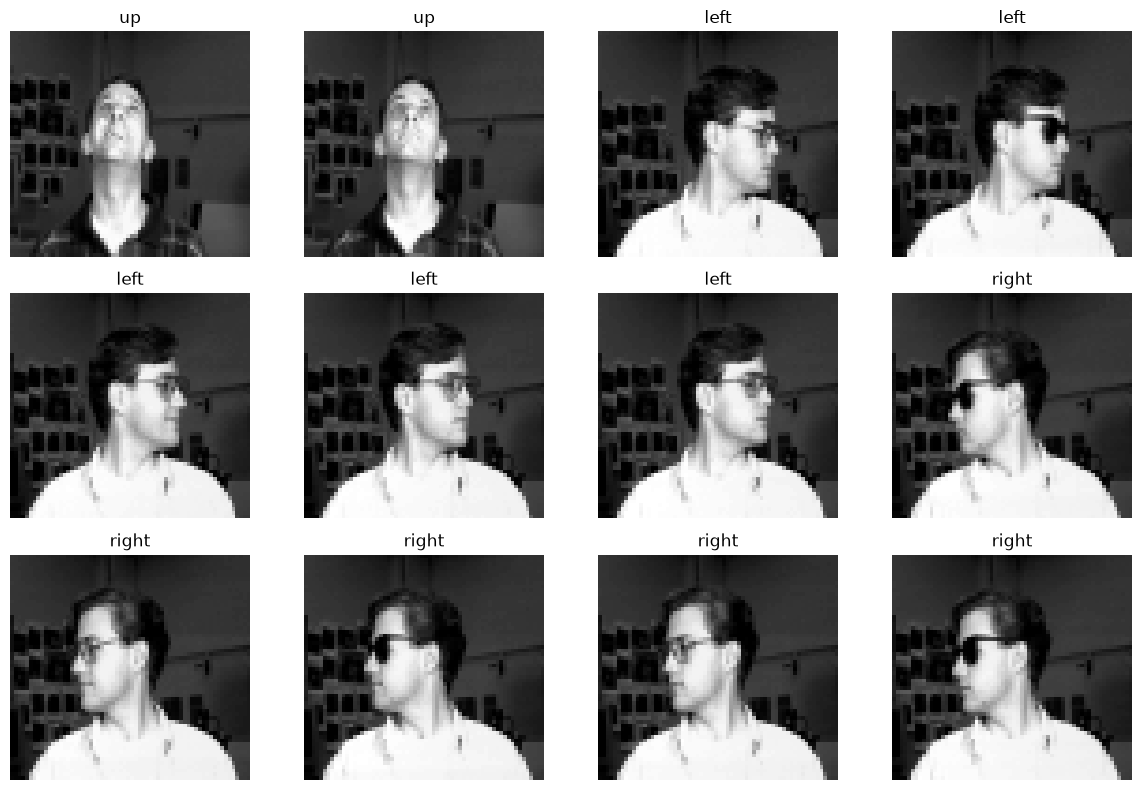

In [8]:
import matplotlib.pyplot as plt

# Number of images to display
num_images = 12
start_image_index = 60  # Starting index for displaying images

plt.figure(figsize=(12, 8))

for i in range(num_images):
    plt.subplot(3, 4, i + 1)

    plt.imshow(X_train[i+start_image_index].squeeze(), cmap="gray")
    plt.title(CLASS_NAMES[y_train[i+start_image_index]])
    plt.axis("off")

plt.tight_layout()
plt.show()

Model B Implementation

In [16]:
from tensorflow.keras import layers, models

model_B = models.Sequential([
    layers.Input(shape=(60, 64, 1)),

    layers.SeparableConv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.SeparableConv2D(64, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.SeparableConv2D(128, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.SeparableConv2D(192, 3, padding="same", activation="relu"),

    layers.GlobalAveragePooling2D(),

    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(4, activation="softmax")
])

#Model B with Batch Normalization and ReLU activation
# model_B = models.Sequential([
#     layers.Input(shape=(60, 64, 1)),

#     # Block 1
#     layers.SeparableConv2D(32, 3, padding="same", use_bias=False),
#     layers.BatchNormalization(),
#     layers.ReLU(),
#     layers.MaxPooling2D(2),

#     # Block 2
#     layers.SeparableConv2D(64, 3, padding="same", use_bias=False),
#     layers.BatchNormalization(),
#     layers.ReLU(),
#     layers.MaxPooling2D(2),

#     # Block 3
#     layers.SeparableConv2D(128, 3, padding="same", use_bias=False),
#     layers.BatchNormalization(),
#     layers.ReLU(),
#     layers.MaxPooling2D(2),

#     # Block 4
#     layers.SeparableConv2D(192, 3, padding="same", use_bias=False),
#     layers.BatchNormalization(),
#     layers.ReLU(),

#     # Classification
#     layers.GlobalAveragePooling2D(),

#     layers.Dense(128, activation="relu"),
#     layers.Dropout(0.3),

#     layers.Dense(4, activation="softmax")
# ])

model_B.summary()
print("Total parameters:", model_B.count_params())



# Compile Model B
from tensorflow.keras.optimizers import Adam

model_B.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)




# Train Model B
history_B = model_B.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=150,
    batch_size=32,
    verbose=1
)



Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ separable_conv2d_16             │ (None, 60, 64, 32)     │            73 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 30, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_17             │ (None, 30, 32, 64)     │         2,400 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 15, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_18             │ (None, 15, 16, 128)    │         8,896 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 7, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_19             │ (None, 7, 8, 192)      │        25,920 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 192)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 62,509 (244.18 KB)

 Trainable params: 62,509 (244.18 KB)

 Non-trainable params: 0 (0.00 B)

Total parameters: 62509
Epoch 1/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.2431 - loss: 1.3870 - val_accuracy: 0.2796 - val_loss: 1.3860
Epoch 2/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2592 - loss: 1.3861 - val_accuracy: 0.2796 - val_loss: 1.3866
Epoch 3/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2248 - loss: 1.3864 - val_accuracy: 0.2043 - val_loss: 1.3867
Epoch 4/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2523 - loss: 1.3864 - val_accuracy: 0.2043 - val_loss: 1.3867
Epoch 5/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.2385 - loss: 1.3862 - val_accuracy: 0.2043 - val_loss: 1.3870
Epoch 6/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.2477 - loss: 1.3863 - val_accuracy: 0.2043 - val_loss: 1.3870
Epoch 7/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.2362 - loss: 1.3867 - val_accuracy: 0.2473 - val_loss: 1.3869
Epoch 8/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2523 - loss: 

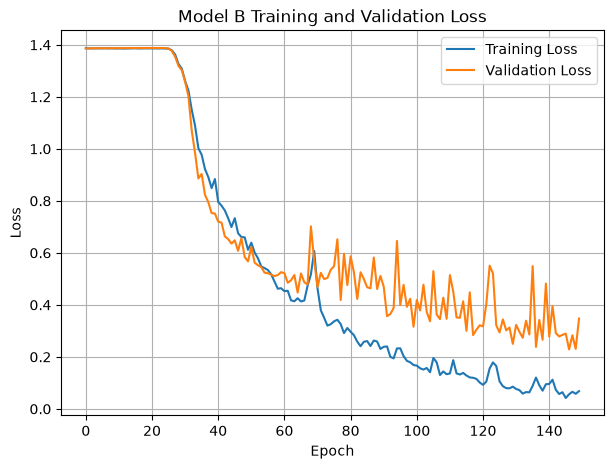

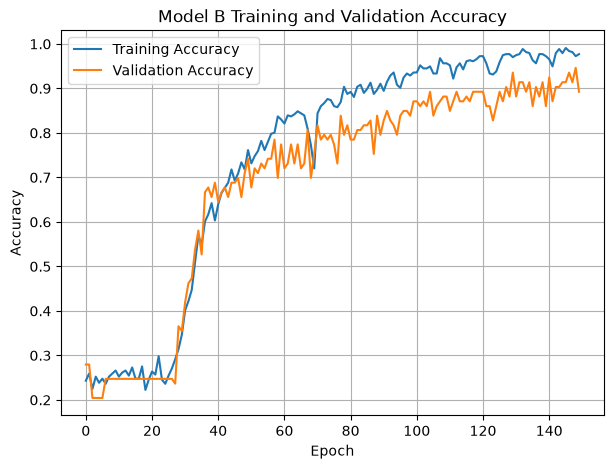

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8737 - loss: 0.5239
Test Loss: 0.5239
Test Accuracy: 0.8737
Test Accuracy: 87.37%
1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/stepWARNING:tensorflow:6 out of the last 9 calls to <function TensorFlowTrainer.make_predict_function.<locals>.one_step_on_data_distributed at 0x000002920DD40040> triggered tf.function retracing. Tracing is expensive and the excessive number of tracings could be due to (1) creating @tf.function repeatedly in a loop, (2) passing tensors with different shapes, (3) passing Python objects instead of tensors. For (1), please define your @tf.function outside of the loop. For (2), @tf.function has reduce_retracing=True option that can avoid unnecessary retracing. For (3), please refer to https://www.tensorflow.org/guide/function#controlling_retracing and https://www.tensorflow.org/api_docs/python/tf/function for  more details.
3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step


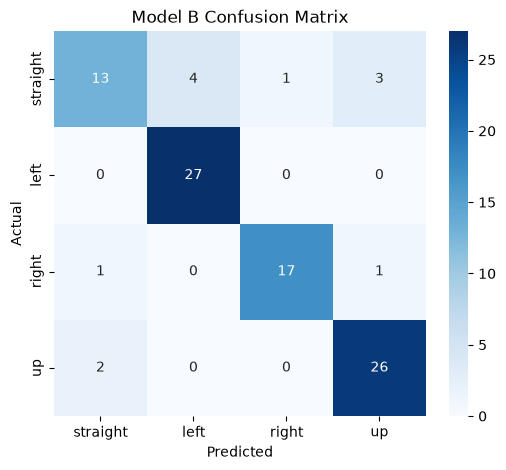

              precision    recall  f1-score   support

    straight     0.8125    0.6190    0.7027        21
        left     0.8710    1.0000    0.9310        27
       right     0.9444    0.8947    0.9189        19
          up     0.8667    0.9286    0.8966        28

    accuracy                         0.8737        95
   macro avg     0.8736    0.8606    0.8623        95
weighted avg     0.8715    0.8737    0.8680        95



In [17]:
import matplotlib.pyplot as plt

# Model B Performance Plots
plt.figure(figsize=(7,5))
plt.plot(history_B.history["loss"], label="Training Loss")
plt.plot(history_B.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Model B Training and Validation Loss")
plt.legend()
plt.grid()
plt.show()


plt.figure(figsize=(7,5))
plt.plot(history_B.history["accuracy"], label="Training Accuracy")
plt.plot(history_B.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model B Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()



# Evaluate Model B on Test Set
test_loss, test_accuracy = model_B.evaluate(
    X_test, y_test,
    verbose=1
)

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")
print(f"Test Accuracy: {test_accuracy*100:.2f}%")


# Genarate Predictions
y_pred_prob = model_B.predict(X_test)
y_pred = np.argmax(y_pred_prob, axis=1)

from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=CLASS_NAMES,
    yticklabels=CLASS_NAMES
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Model B Confusion Matrix")
plt.show()

print(classification_report(
    y_test,
    y_pred,
    target_names=CLASS_NAMES,
    digits=4
))



Comparison with SGD and SGD with momentum

In [18]:
model_B.save("model_B.keras")

Training with SGD...
Epoch 1/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 0.2271 - loss: 1.3960 - val_accuracy: 0.2043 - val_loss: 1.4047
Epoch 2/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2156 - loss: 1.3950 - val_accuracy: 0.2043 - val_loss: 1.4033
Epoch 3/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2156 - loss: 1.3939 - val_accuracy: 0.2043 - val_loss: 1.4012
Epoch 4/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.2156 - loss: 1.3936 - val_accuracy: 0.2043 - val_loss: 1.4010
Epoch 5/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2156 - loss: 1.3932 - val_accuracy: 0.2043 - val_loss: 1.4011
Epoch 6/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step - accuracy: 0.2156 - loss: 1.3934 - val_accuracy: 0.2043 - val_loss: 1.4009
Epoch 7/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.2156 - loss: 1.3934 - val_accuracy: 0.2043 - val_loss: 1.4009
Epoch 8/150
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step - accuracy: 0.2156 - loss: 1.39

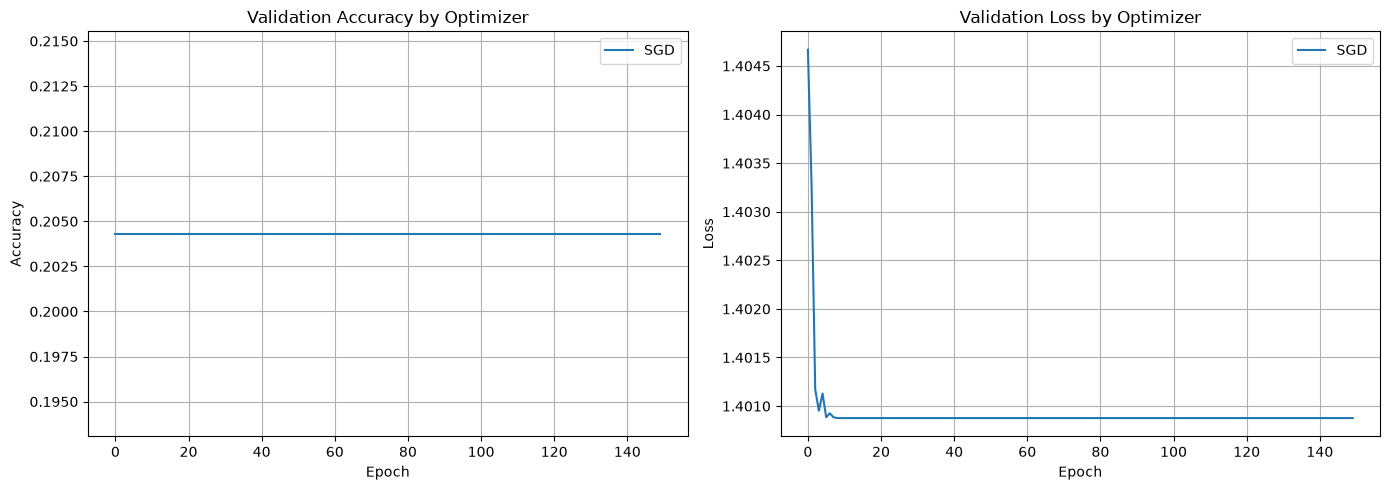

In [ ]:
import tensorflow as tf
from tensorflow.keras.models import clone_model
from tensorflow.keras.optimizers import Adam, SGD

# Retrain all three optimizers from identical initial weights for a fair comparison.
tf.keras.utils.set_random_seed(42)
initialization_model = clone_model(model_B)
initial_weights = initialization_model.get_weights()

optimizer_configs = {
    "Adam": Adam(learning_rate=0.001),
    "SGD": SGD(learning_rate=0.1),
    "SGD with Momentum": SGD(learning_rate=0.1, momentum=0.9),
}

comparison_histories = {}

for optimizer_name, optimizer in optimizer_configs.items():
    comparison_model = clone_model(model_B)
    comparison_model.set_weights(initial_weights)
    comparison_model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )

    print(f"Training with {optimizer_name}...")
    comparison_histories[optimizer_name] = comparison_model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=150,
        batch_size=32,
        verbose=1,
    )

# Compare validation performance for all three optimizers.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for optimizer_name, history in comparison_histories.items():
    axes[0].plot(history.history["val_accuracy"], label=optimizer_name)
    axes[1].plot(history.history["val_loss"], label=optimizer_name)

axes[0].set_title("Validation Accuracy by Optimizer")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Validation Loss by Optimizer")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()